<a href="https://colab.research.google.com/github/nguyenngocvuong2006-oss/TH_AI/blob/main/Bai_4_MLP_voi_du_lieu_anh_BaiTap_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BÀI 4. XÂY DỰNG MÔ HÌNH MLP CHO DỮ LIỆU ẢNH
## Trọng tâm: Workflow Deep Learning hoàn chỉnh

**Mục tiêu bài thực hành**

Sau bài này, sinh viên có thể:

1. Hiểu dữ liệu ảnh được biểu diễn dưới dạng tensor như thế nào.
2. Tách dữ liệu thành **training / validation / test** đúng vai trò.
3. Tiền xử lý dữ liệu phù hợp cho mạng nơ-ron.
4. Xây dựng một mô hình **Multi-Layer Perceptron (MLP)** bằng TensorFlow/Keras.
5. Hiểu quy trình **compile → train → validate → evaluate → predict**.
6. Theo dõi quá trình học qua **loss curve** và **accuracy curve**.
7. Nhận biết dấu hiệu **underfitting / overfitting**.
8. Sử dụng callback như **EarlyStopping** và **ModelCheckpoint**.
9. Đánh giá mô hình bằng accuracy, confusion matrix và classification report.
10. Thực hiện inference trên ảnh mới và lưu/khôi phục mô hình.

---

### Bộ dữ liệu sử dụng: Fashion-MNIST

Fashion-MNIST gồm ảnh xám kích thước **28×28**, thuộc **10 lớp** trang phục.

Bộ dữ liệu này phù hợp để học MLP vì:
- dữ liệu đủ nhỏ để huấn luyện nhanh trên Colab;
- khó hơn MNIST chữ số;
- ảnh có cấu trúc rõ ràng;
- MLP có thể xử lý trực tiếp sau khi làm phẳng ảnh thành vector.

> **Lưu ý:** MLP không khai thác tốt cấu trúc không gian của ảnh như CNN. Trong bài này, MLP được dùng để tập trung vào **workflow của Deep Learning**. CNN sẽ là bước tiếp theo tự nhiên.

## 1. Chuẩn bị môi trường và thư viện

Trong Deep Learning, chúng ta thường cần:

- thư viện xử lý số liệu;
- thư viện trực quan hóa;
- framework Deep Learning;
- công cụ đánh giá mô hình.

In [32]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


### Hướng dẫn đọc kết quả

- `TensorFlow version` cho biết phiên bản framework đang sử dụng.
- `GPU available` cho biết Colab có nhận GPU hay không.
- Với Fashion-MNIST và MLP nhỏ, CPU vẫn có thể chạy được; tuy nhiên GPU giúp huấn luyện nhanh hơn.

### Phân tích thực tế

Trong các dự án Deep Learning lớn, môi trường tính toán ảnh hưởng trực tiếp đến thời gian huấn luyện. Vì vậy, kiểm tra GPU là một bước quen thuộc trước khi bắt đầu.

## 2. Thiết lập random seed để tăng khả năng tái lập kết quả

Deep Learning có nhiều yếu tố ngẫu nhiên:
- khởi tạo trọng số;
- thứ tự mini-batch;
- một số phép toán trên GPU.

Đặt seed giúp các lần chạy cho kết quả gần nhau hơn.

In [33]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed =", SEED)

Random seed = 42


### Hướng dẫn đọc kết quả

Nếu notebook được chạy lại với cùng seed, quá trình huấn luyện thường cho kết quả gần tương tự.

### Phân tích thực tế

Không nên hiểu seed là đảm bảo 100% mọi lần chạy giống hệt nhau trên mọi phần cứng. Tuy nhiên, đây là bước quan trọng để thí nghiệm có tính **reproducibility**.

## 3. Tải dữ liệu Fashion-MNIST

Keras cung cấp sẵn Fashion-MNIST nên không cần tải file thủ công.

Dữ liệu gốc đã được chia thành:
- **60,000 ảnh training**
- **10,000 ảnh test**

Sau đó ta sẽ tiếp tục tách một phần training thành validation.

In [34]:
fashion_mnist = tf.keras.datasets.fashion_mnist

(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

print("X_train_full:", X_train_full.shape)
print("y_train_full:", y_train_full.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)
print("Kiểu dữ liệu ảnh:", X_train_full.dtype)
print("Khoảng giá trị pixel:", X_train_full.min(), "->", X_train_full.max())

X_train_full: (60000, 28, 28)
y_train_full: (60000,)
X_test: (10000, 28, 28)
y_test: (10000,)
Kiểu dữ liệu ảnh: uint8
Khoảng giá trị pixel: 0 -> 255


### Hướng dẫn đọc kết quả

- `(60000, 28, 28)` nghĩa là có 60,000 ảnh, mỗi ảnh kích thước 28×28.
- Nhãn có dạng vector 1 chiều, mỗi phần tử là một số nguyên từ 0 đến 9.
- Pixel ảnh gốc nằm trong khoảng **0–255**.

### Phân tích thực tế

Ảnh không phải là một bảng feature được thiết kế sẵn như bài hồi quy hay classification trước. Mỗi pixel chính là một giá trị đầu vào. Đây là điểm chuyển quan trọng từ dữ liệu bảng sang dữ liệu ảnh.

## 4. Khám phá nhanh dữ liệu ảnh

Ở bài này chúng ta **không tập trung vào EDA sâu** như với dữ liệu bảng.  
Mục đích của bước này chỉ là:

1. hiểu ảnh trông như thế nào;
2. kiểm tra nhãn;
3. kiểm tra phân bố lớp;
4. xác nhận dữ liệu hợp lý trước khi huấn luyện.

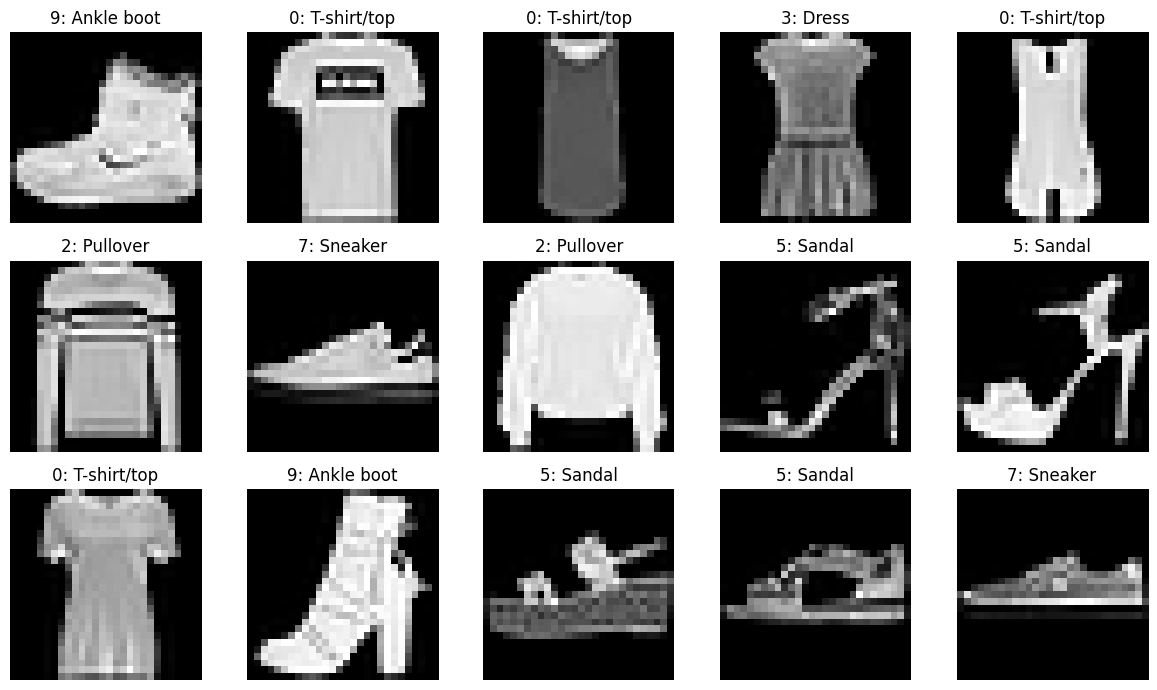

In [35]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

fig, axes = plt.subplots(3, 5, figsize=(12, 7))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(X_train_full[i], cmap="gray")
    ax.set_title(f"{y_train_full[i]}: {class_names[y_train_full[i]]}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Hướng dẫn đọc kết quả

Mỗi ảnh được hiển thị cùng:
- mã nhãn;
- tên lớp tương ứng.

### Phân tích thực tế

Ảnh Fashion-MNIST khá nhỏ và không chứa màu. Một số lớp có hình dạng gần nhau như:
- `T-shirt/top`;
- `Shirt`;
- `Pullover`;
- `Coat`.

Do đó đây là bài toán khó hơn nhận dạng chữ số MNIST.

In [36]:
unique, counts = np.unique(y_train_full, return_counts=True)

class_distribution = pd.DataFrame({
    "class_id": unique,
    "class_name": [class_names[i] for i in unique],
    "count": counts
})

display(class_distribution)

,class_id,class_name,count
0,0,T-shirt/top,6000
1,1,Trouser,6000
2,2,Pullover,6000
3,3,Dress,6000
4,4,Coat,6000
5,5,Sandal,6000
6,6,Shirt,6000
7,7,Sneaker,6000
8,8,Bag,6000
9,9,Ankle boot,6000


### Hướng dẫn đọc kết quả

Bảng cho biết số mẫu của từng lớp.

### Phân tích thực tế

Fashion-MNIST được xây dựng khá cân bằng, nên ở bài này **không cần sampling để xử lý class imbalance** như bài 3. Điều đó giúp ta tập trung vào quy trình huấn luyện Deep Learning.

## 5. Tách Training / Validation / Test

Trong Deep Learning, ba tập dữ liệu có vai trò khác nhau:

- **Training set**: dùng để cập nhật trọng số mô hình bằng gradient descent.
- **Validation set**: dùng để theo dõi khả năng tổng quát hóa trong quá trình huấn luyện và lựa chọn epoch/hyperparameter.
- **Test set**: chỉ dùng ở cuối để đánh giá mô hình đã hoàn thiện.

> Không nên dùng test set để điều chỉnh mô hình.

In [37]:
VAL_SIZE = 10_000

X_val = X_train_full[-VAL_SIZE:]
y_val = y_train_full[-VAL_SIZE:]

X_train = X_train_full[:-VAL_SIZE]
y_train = y_train_full[:-VAL_SIZE]

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Training: (50000, 28, 28) (50000,)
Validation: (10000, 28, 28) (10000,)
Test: (10000, 28, 28) (10000,)


### Hướng dẫn đọc kết quả

Ta thu được:
- 50,000 mẫu training;
- 10,000 mẫu validation;
- 10,000 mẫu test.

### Phân tích thực tế

Validation set đóng vai trò rất quan trọng trong Deep Learning vì một mô hình có thể tiếp tục giảm training loss nhưng bắt đầu tăng validation loss. Đó là dấu hiệu overfitting.

## 6. Chuẩn hóa dữ liệu ảnh

Mỗi pixel ban đầu nằm trong khoảng `[0, 255]`.

Ta chuyển sang `float32` và chia cho 255 để đưa dữ liệu về `[0, 1]`.

Việc chuẩn hóa giúp:
- gradient ổn định hơn;
- tối ưu dễ hơn;
- các layer nhận dữ liệu ở thang đo phù hợp.

In [38]:
X_train = X_train.astype("float32") / 255.0
X_val = X_val.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

print("Training min/max:", X_train.min(), X_train.max())
print("Validation min/max:", X_val.min(), X_val.max())
print("Test min/max:", X_test.min(), X_test.max())

Training min/max: 0.0 1.0
Validation min/max: 0.0 1.0
Test min/max: 0.0 1.0


### Hướng dẫn đọc kết quả

Sau chuẩn hóa:
- giá trị nhỏ nhất ≈ 0;
- giá trị lớn nhất ≈ 1.

### Phân tích thực tế

Trong Deep Learning, scale dữ liệu thường ảnh hưởng mạnh đến tốc độ hội tụ. Với ảnh xám, chia cho 255 là cách chuẩn hóa đơn giản và hiệu quả.

## 7. Tạo input pipeline bằng `tf.data`

Deep Learning thường huấn luyện bằng **mini-batch**, không đưa toàn bộ dữ liệu vào mô hình cùng lúc.

`tf.data.Dataset` giúp:
- tạo batch;
- shuffle dữ liệu;
- prefetch dữ liệu;
- xây dựng pipeline có thể mở rộng cho dữ liệu lớn.

In [39]:
BATCH_SIZE = 64

train_ds = (
    tf.data.Dataset.from_tensor_slices((X_train, y_train))
    .shuffle(buffer_size=len(X_train), seed=SEED)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices((X_val, y_val))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

for images, labels in train_ds.take(1):
    print("Batch images shape:", images.shape)
    print("Batch labels shape:", labels.shape)

Batch images shape: (64, 28, 28)
Batch labels shape: (64,)


### Hướng dẫn đọc kết quả

Một batch có dạng:

- ảnh: `(batch_size, 28, 28)`
- nhãn: `(batch_size,)`

### Phân tích thực tế

Mini-batch là đơn vị cơ bản của quá trình huấn luyện Deep Learning. Mỗi batch đi qua:
1. forward pass;
2. tính loss;
3. backpropagation;
4. cập nhật trọng số.

Sau khi đi hết mọi batch, ta hoàn thành **1 epoch**.

## 8. Xây dựng mô hình MLP

Ảnh có dạng ma trận `28 × 28`.  
MLP yêu cầu vector đầu vào, nên trước hết cần **Flatten** ảnh:

\[
28 \times 28 = 784
\]

Sau đó dữ liệu đi qua các Dense layer:

\[
784 \rightarrow 256 \rightarrow 128 \rightarrow 10
\]

Layer cuối có 10 neuron, tương ứng 10 lớp.

In [40]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dense(128, activation="relu"),

    tf.keras.layers.Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

### Hướng dẫn đọc kết quả

`model.summary()` cho biết:
- tên từng layer;
- kích thước output;
- số parameter cần học.

Dense layer có số tham số:

`input_size × output_size + bias`

### Phân tích thực tế

Số parameter của MLP có thể khá lớn dù ảnh chỉ 28×28. Nguyên nhân là mỗi neuron Dense kết nối với toàn bộ đầu vào. Đây cũng là một lý do CNN thường hiệu quả hơn cho dữ liệu ảnh.

## 9. Compile mô hình

Trước khi train, cần xác định ba thành phần:

1. **Optimizer** – cách cập nhật trọng số.
2. **Loss function** – hàm mục tiêu cần tối thiểu hóa.
3. **Metric** – chỉ số theo dõi hiệu năng.

Ở đây sử dụng:

- Optimizer: `Adam`
- Loss: `SparseCategoricalCrossentropy`
- Metric: `accuracy`

Vì nhãn được lưu dưới dạng số nguyên `0...9`, ta dùng **sparse categorical cross-entropy**.

In [41]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


### Hướng dẫn đọc kết quả

Nếu cell chạy không lỗi, mô hình đã sẵn sàng để huấn luyện.

### Phân tích thực tế

`compile()` không huấn luyện mô hình. Nó chỉ thiết lập quy tắc huấn luyện. Việc cập nhật trọng số chỉ xảy ra khi gọi `fit()`.

## 10. Callback trong Deep Learning

Huấn luyện mạng nơ-ron có thể kéo dài nhiều epoch. Callback giúp kiểm soát quá trình này.

Ta sử dụng:

### EarlyStopping
Dừng huấn luyện khi validation loss không còn cải thiện.

### ModelCheckpoint
Lưu lại mô hình có validation loss tốt nhất.

Đây là workflow phổ biến trong thực tế để tránh giữ mô hình ở epoch cuối nếu epoch đó đã overfit.

In [42]:
checkpoint_path = "best_mlp_fashion.keras"

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor="val_loss",
        save_best_only=True
    )
]

print("Callbacks ready.")

Callbacks ready.


## 11. Huấn luyện mô hình

Trong mỗi epoch:

1. mô hình chạy qua toàn bộ training set;
2. optimizer cập nhật trọng số theo từng mini-batch;
3. cuối epoch, mô hình được đánh giá trên validation set.

Ta theo dõi đồng thời:
- `loss`;
- `accuracy`;
- `val_loss`;
- `val_accuracy`.

In [43]:
EPOCHS = 40

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8202 - loss: 0.5029 - val_accuracy: 0.8474 - val_loss: 0.4315
Epoch 2/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8636 - loss: 0.3710 - val_accuracy: 0.8703 - val_loss: 0.3579
Epoch 3/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8778 - loss: 0.3310 - val_accuracy: 0.8700 - val_loss: 0.3453
Epoch 4/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8877 - loss: 0.3042 - val_accuracy: 0.8701 - val_loss: 0.3507
Epoch 5/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - accuracy: 0.8945 - loss: 0.2851 - val_accuracy: 0.8860 - val_loss: 0.3171
Epoch 6/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8997 - loss: 0.2723 - val_accuracy: 0.8831 - val_loss: 0.3217
Epoch 7/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9026 - loss: 0.2603 - val_accuracy: 0.8870 - val_loss: 0.3067
Epoch 8/40
782/782 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9082 - loss: 0.2455 - val_accuracy: 0.

### Hướng dẫn đọc kết quả

Mỗi dòng epoch thường có:

- `loss`: training loss;
- `accuracy`: training accuracy;
- `val_loss`: validation loss;
- `val_accuracy`: validation accuracy.

### Phân tích thực tế

Một quá trình học tốt thường có:
- training loss giảm;
- validation loss cũng giảm trong giai đoạn đầu;
- accuracy tăng dần.

Nếu training loss tiếp tục giảm nhưng validation loss tăng, mô hình đang **overfitting**.

## 12. Trực quan hóa learning curves

Learning curve là công cụ quan trọng để đọc quá trình huấn luyện Deep Learning.

Ta sẽ vẽ:
- Loss theo epoch;
- Accuracy theo epoch.

In [44]:
history_df = pd.DataFrame(history.history)
display(history_df.tail())

,accuracy,loss,val_accuracy,val_loss
7,0.90820,0.245536,0.8880,0.309214
8,0.91130,0.236829,0.8885,0.306697
9,0.91504,0.227881,0.8928,0.309918
10,0.91890,0.217917,0.8909,0.325406
11,0.92060,0.208862,0.8851,0.334474


### Hướng dẫn đọc kết quả

Mỗi dòng tương ứng một epoch.  
Bảng này là dữ liệu nguồn để phân tích quá trình học.

### Phân tích thực tế

Không nên chỉ nhìn accuracy cuối cùng. Lịch sử training giúp ta biết:
- mô hình học nhanh hay chậm;
- bắt đầu overfit ở epoch nào;
- callback có dừng hợp lý không.

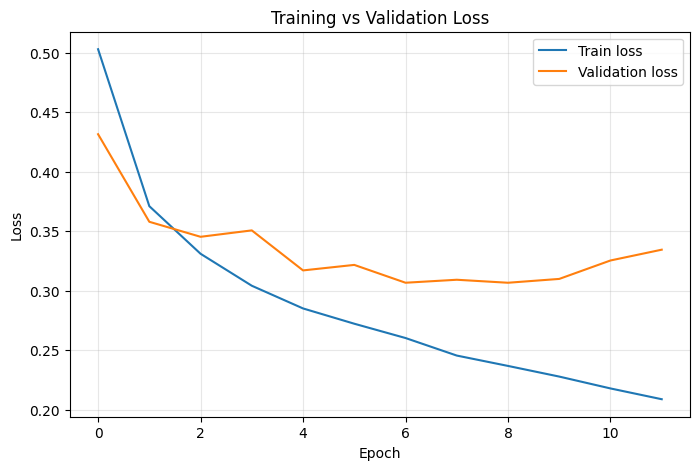

In [45]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Train loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Hướng dẫn đọc kết quả

- Đường train loss cho biết mức lỗi trên training set.
- Đường validation loss cho biết khả năng tổng quát hóa trên dữ liệu chưa dùng để cập nhật trọng số.

### Phân tích thực tế

- Hai đường cùng giảm: mô hình đang học tốt.
- Train loss giảm nhưng val loss tăng: overfitting.
- Cả hai đều cao và gần nhau: có thể underfitting.

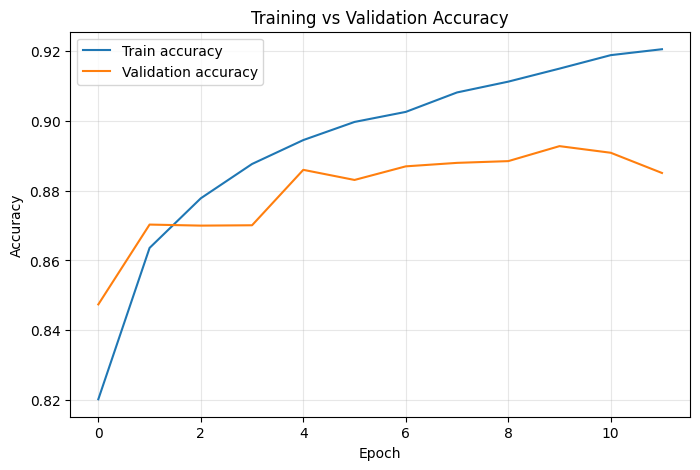

In [46]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Hướng dẫn đọc kết quả

So sánh khoảng cách giữa training accuracy và validation accuracy.

### Phân tích thực tế

Khoảng cách nhỏ thường cho thấy mô hình tổng quát hóa tương đối tốt. Nếu training accuracy cao hơn validation accuracy quá nhiều, mô hình có thể đang ghi nhớ training set.

## 13. Đánh giá cuối cùng trên Test Set

Sau khi quá trình train và lựa chọn mô hình hoàn tất, ta mới đánh giá trên test set.

Test set đóng vai trò như dữ liệu hoàn toàn mới.

In [47]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)

print(f"Test loss     : {test_loss:.4f}")
print(f"Test accuracy : {test_accuracy:.4f}")

Test loss     : 0.3304
Test accuracy : 0.8841


### Hướng dẫn đọc kết quả

`Test accuracy` là tỷ lệ dự đoán đúng trên dữ liệu test.

### Phân tích thực tế

Nếu validation accuracy và test accuracy gần nhau, kết quả validation có khả năng phản ánh tốt khả năng tổng quát hóa. Nếu test accuracy giảm mạnh, quy trình tuning có thể đã phụ thuộc quá nhiều vào validation set.

## 14. Dự đoán xác suất và nhãn lớp

Layer cuối dùng Softmax nên mô hình trả về một vector xác suất cho 10 lớp.

Ví dụ:

`[0.01, 0.00, 0.02, ..., 0.90]`

Lớp có xác suất lớn nhất được chọn làm dự đoán.

In [48]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Probability shape:", y_prob.shape)
print("5 nhãn thật đầu tiên:", y_test[:5])
print("5 nhãn dự đoán đầu tiên:", y_pred[:5])

Probability shape: (10000, 10)
5 nhãn thật đầu tiên: [9 2 1 1 6]
5 nhãn dự đoán đầu tiên: [9 2 1 1 6]


### Hướng dẫn đọc kết quả

- `y_prob.shape = (10000, 10)` nghĩa là mỗi ảnh có 10 xác suất.
- `argmax` lấy vị trí có xác suất lớn nhất làm nhãn dự đoán.

### Phân tích thực tế

Trong nhiều ứng dụng, xác suất dự đoán cũng quan trọng như nhãn cuối cùng vì nó cho biết độ tự tin tương đối của mô hình.

## 15. Confusion Matrix

Accuracy cho biết hiệu quả tổng thể, nhưng không cho biết mô hình nhầm lớp nào với lớp nào.

Confusion matrix giúp phân tích lỗi chi tiết hơn.

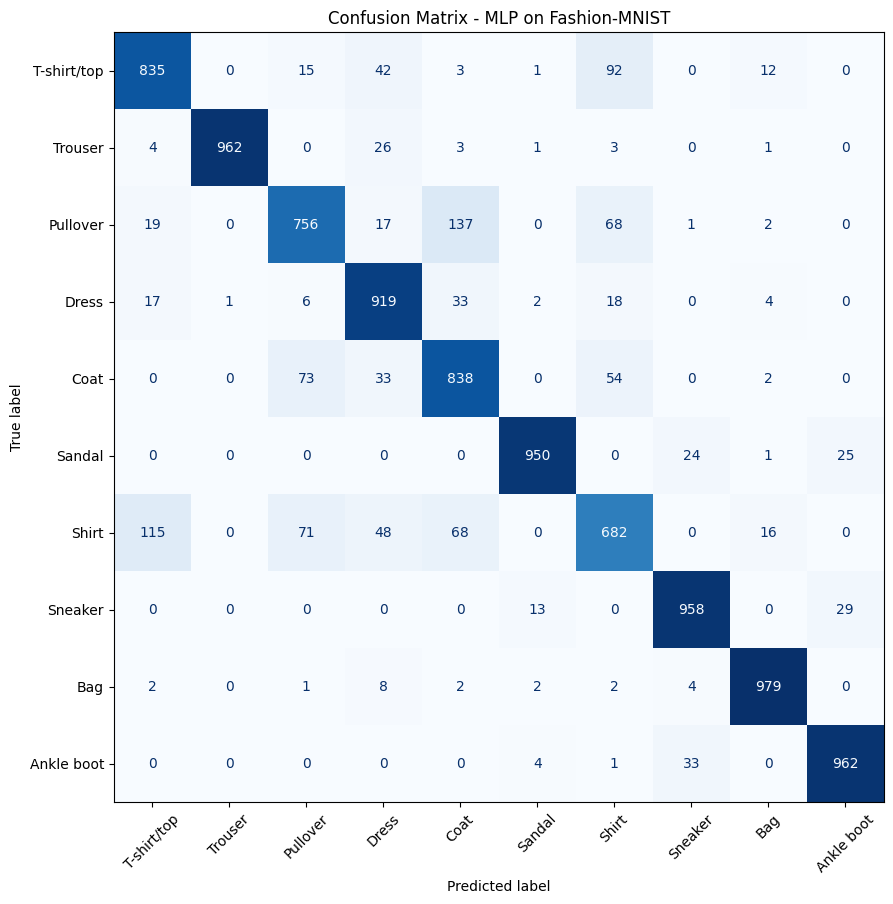

In [49]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 10))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, xticks_rotation=45, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - MLP on Fashion-MNIST")
plt.show()

### Hướng dẫn đọc kết quả

- Giá trị trên đường chéo: số mẫu dự đoán đúng.
- Giá trị ngoài đường chéo: các trường hợp bị nhầm lớp.

### Phân tích thực tế

Với Fashion-MNIST, mô hình thường dễ nhầm các nhóm có hình dạng tương tự nhau như:
- Shirt và T-shirt/top;
- Shirt và Pullover;
- Coat và Pullover.

Confusion matrix cho phép nhìn rõ loại lỗi này hơn accuracy.

## 16. Classification Report

Ta xem thêm:
- precision;
- recall;
- F1-score;
- support.

Mục tiêu ở đây không phải học lại toàn bộ metric của bài 3, mà là biết cách kiểm tra hiệu năng theo từng lớp.

In [50]:
report = classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
)

print(report)

              precision    recall  f1-score   support

 T-shirt/top     0.8417    0.8350    0.8384      1000
     Trouser     0.9990    0.9620    0.9801      1000
    Pullover     0.8200    0.7560    0.7867      1000
       Dress     0.8408    0.9190    0.8782      1000
        Coat     0.7731    0.8380    0.8042      1000
      Sandal     0.9764    0.9500    0.9630      1000
       Shirt     0.7413    0.6820    0.7104      1000
     Sneaker     0.9392    0.9580    0.9485      1000
         Bag     0.9626    0.9790    0.9707      1000
  Ankle boot     0.9469    0.9620    0.9544      1000

    accuracy                         0.8841     10000
   macro avg     0.8841    0.8841    0.8835     10000
weighted avg     0.8841    0.8841    0.8835     10000



### Hướng dẫn đọc kết quả

- `precision`: trong các mẫu mô hình dự đoán là một lớp, bao nhiêu mẫu đúng.
- `recall`: trong các mẫu thực sự thuộc lớp đó, mô hình tìm đúng bao nhiêu.
- `f1-score`: cân bằng precision và recall.

### Phân tích thực tế

Dù dữ liệu cân bằng, một số lớp vẫn có F1 thấp hơn vì bản thân hình ảnh giữa các lớp đó khó phân biệt.

## 17. Trực quan hóa các dự đoán

Ta hiển thị một số ảnh cùng:
- nhãn thật;
- nhãn dự đoán;
- xác suất cao nhất.

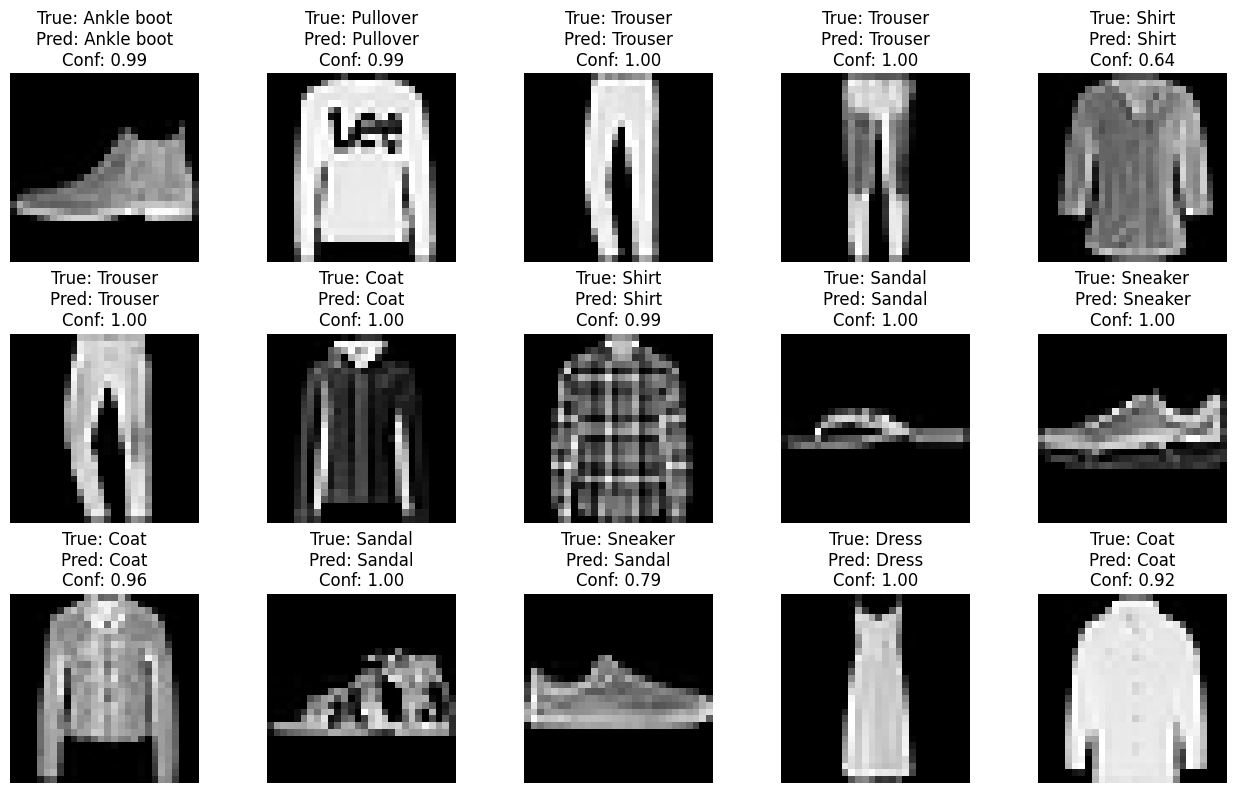

In [51]:
indices = np.arange(15)

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(indices, axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Hướng dẫn đọc kết quả

Mỗi ảnh cho biết:
- lớp thật;
- lớp mô hình chọn;
- confidence của lớp được chọn.

### Phân tích thực tế

Các mẫu dự đoán sai nhưng confidence cao là những ví dụ rất quan trọng để phân tích lỗi mô hình. Trong các bài toán thực tế, đây thường là nhóm cần được điều tra sâu hơn.

## 18. Phân tích các mẫu dự đoán sai

Thay vì chỉ xem accuracy, ta chủ động tìm các ảnh mà mô hình dự đoán sai.

Số mẫu dự đoán sai: 1159


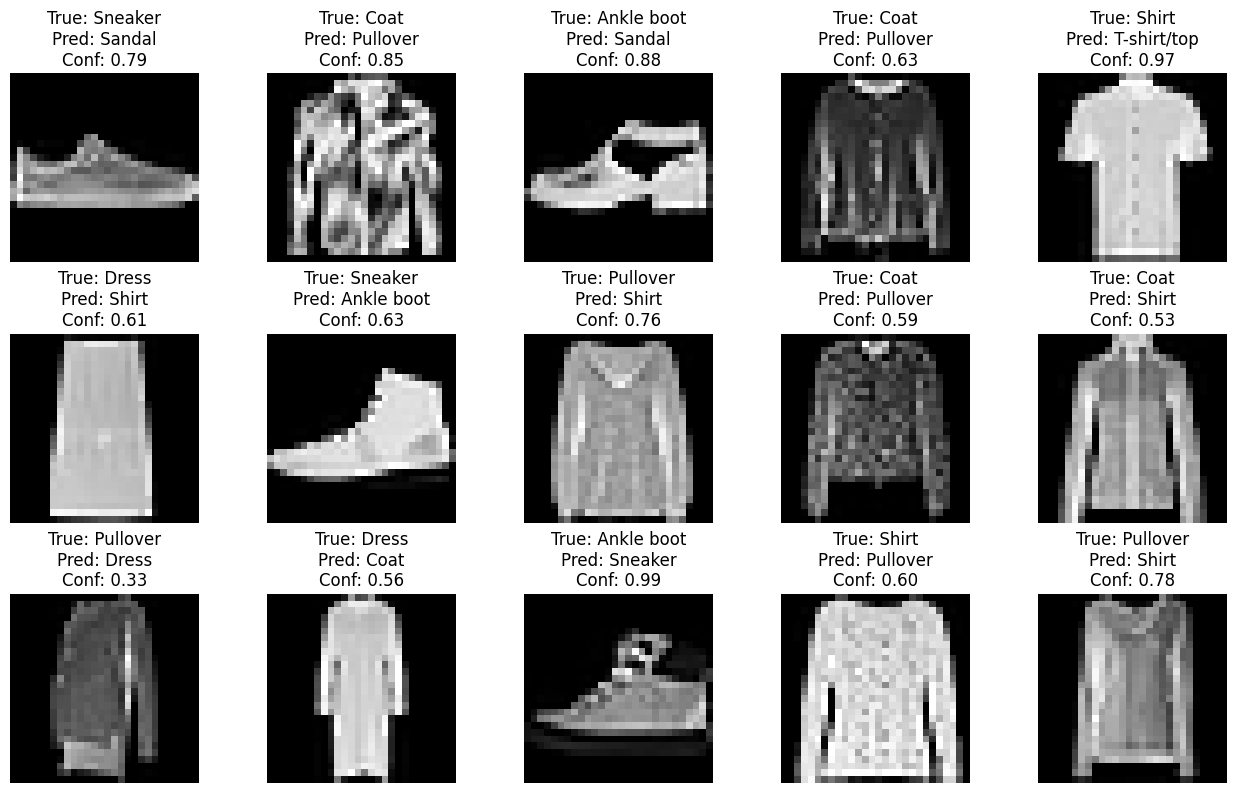

In [52]:
wrong_indices = np.where(y_pred != y_test)[0]

print("Số mẫu dự đoán sai:", len(wrong_indices))

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for idx, ax in zip(wrong_indices[:15], axes.ravel()):
    true_label = y_test[idx]
    pred_label = y_pred[idx]
    confidence = y_prob[idx][pred_label]

    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(
        f"True: {class_names[true_label]}\n"
        f"Pred: {class_names[pred_label]}\n"
        f"Conf: {confidence:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

### Hướng dẫn đọc kết quả

Chỉ các mẫu mô hình dự đoán sai được hiển thị.

### Phân tích thực tế

Error analysis là bước quan trọng của workflow Deep Learning. Từ lỗi thực tế, ta mới quyết định có cần:
- mô hình sâu hơn;
- regularization;
- thêm dữ liệu;
- data augmentation;
- đổi kiến trúc sang CNN.

## 19. Inference trên một ảnh riêng lẻ

Trong thực tế, mô hình thường nhận một hoặc một vài mẫu mới chứ không phải cả test set.

Ta chọn một ảnh và mô phỏng quy trình inference.

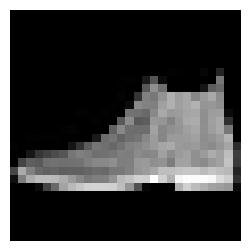

True label : Ankle boot
Prediction : Ankle boot
Confidence : 0.9924702644348145


In [53]:
sample_image = X_test[0]
sample_true_label = y_test[0]

sample_prob = model.predict(sample_image[None, ...], verbose=0)[0]
sample_pred = np.argmax(sample_prob)

plt.figure(figsize=(3, 3))
plt.imshow(sample_image, cmap="gray")
plt.axis("off")
plt.show()

print("True label :", class_names[sample_true_label])
print("Prediction :", class_names[sample_pred])
print("Confidence :", float(sample_prob[sample_pred]))

### Hướng dẫn đọc kết quả

`sample_image[None, ...]` thêm chiều batch:

- trước: `(28, 28)`
- sau: `(1, 28, 28)`

### Phân tích thực tế

Framework Deep Learning thường yêu cầu input có batch dimension ngay cả khi chỉ dự đoán một ảnh.

## 20. Lưu và khôi phục mô hình

Sau khi huấn luyện xong, mô hình cần được lưu để:
- triển khai;
- tiếp tục huấn luyện;
- tái sử dụng sau này.

Keras cho phép lưu toàn bộ kiến trúc và trọng số vào file `.keras`.

In [54]:
final_model_path = "fashion_mnist_mlp_final.keras"

model.save(final_model_path)

loaded_model = tf.keras.models.load_model(final_model_path)

loaded_loss, loaded_acc = loaded_model.evaluate(test_ds, verbose=0)

print("Loaded model test accuracy:", round(float(loaded_acc), 4))

Loaded model test accuracy: 0.8841


### Hướng dẫn đọc kết quả

Nếu accuracy sau khi load gần như giống mô hình trước khi lưu, quá trình lưu/khôi phục đã thành công.

### Phân tích thực tế

Đây là bước nối từ training sang deployment. Trong dự án thật, model artifact cần được quản lý cùng:
- phiên bản dữ liệu;
- hyperparameter;
- code;
- metric.

# 21. Tổng kết workflow Deep Learning

Một workflow Deep Learning điển hình:

**Bước 1. Chuẩn bị dữ liệu**  
↓  
**Bước 2. Train / Validation / Test split**  
↓  
**Bước 3. Tiền xử lý và tạo batch**  
↓  
**Bước 4. Xây dựng kiến trúc mạng**  
↓  
**Bước 5. Compile: optimizer + loss + metric**  
↓  
**Bước 6. Train bằng mini-batch**  
↓  
**Bước 7. Theo dõi validation và callback**  
↓  
**Bước 8. Phân tích learning curves**  
↓  
**Bước 9. Đánh giá trên test set**  
↓  
**Bước 10. Error analysis**  
↓  
**Bước 11. Inference và lưu mô hình**

---

## So sánh nhanh với workflow Machine Learning cổ điển

| Machine Learning cổ điển | Deep Learning |
|---|---|
| Feature engineering thường rất quan trọng | Mô hình học representation từ dữ liệu |
| `fit(X_train, y_train)` thường là một bước tương đối gọn | Training gồm nhiều epoch và mini-batch |
| Ít cần quan sát quá trình tối ưu | Cần theo dõi loss/metric theo epoch |
| Model selection dựa nhiều vào CV | Validation set và learning curve rất quan trọng |
| Model thường nhỏ | Số parameter có thể rất lớn |
| Training nhanh | Training có thể tốn GPU và thời gian |

---

## Câu hỏi thảo luận

1. Vì sao MLP cần `Flatten` ảnh trước Dense layer?
2. Validation set khác test set ở điểm nào?
3. Một epoch là gì? Một batch là gì?
4. Khi nào training loss giảm nhưng validation loss tăng?
5. EarlyStopping giúp giải quyết vấn đề gì?
6. Vì sao không nên dùng test set để chọn hyperparameter?
7. Tại sao MLP chưa phải kiến trúc tối ưu cho ảnh?
8. Nếu tăng số neuron/layer, điều gì có thể xảy ra?
9. Nếu learning rate quá lớn, learning curve có thể có đặc điểm gì?
10. Bước tiếp theo để cải thiện mô hình cho ảnh là kiến trúc nào?

# 22. Bài tập mở rộng cho sinh viên

### Bài 1. Thay đổi kiến trúc
Thử các mô hình:
- 1 hidden layer;
- 2 hidden layers;
- 3 hidden layers.

So sánh:
- số parameter;
- thời gian train;
- validation accuracy;
- test accuracy.

### Bài 2. Thử learning rate
Huấn luyện với:
- `1e-2`
- `1e-3`
- `1e-4`

Nhận xét learning curve.

### Bài 3. Thử batch size
So sánh:
- 32
- 128
- 512

Nhận xét tốc độ và kết quả.

### Bài 4. Thêm Dropout
Thêm `Dropout(0.3)` giữa các Dense layer.  
Quan sát khoảng cách train/validation accuracy.

### Bài 5. Thêm L2 regularization
Dùng `kernel_regularizer=tf.keras.regularizers.l2(...)`.

### Bài 6. Phân tích lỗi
Tìm 20 mẫu mô hình dự đoán sai với confidence cao nhất.  
Phân tích vì sao chúng khó.
---

## Yêu cầu báo cáo ngắn

Sinh viên cần trả lời:

1. Kiến trúc mô hình đã sử dụng.
2. Optimizer, loss, learning rate, batch size.
3. Epoch tốt nhất.
4. Training/validation learning curves.
5. Test accuracy.
6. Hai cặp lớp bị nhầm nhiều nhất.
7. Nhận xét underfitting/overfitting.
8. Một thay đổi đã thử để cải thiện mô hình và kết quả.

---
# LỜI GIẢI BÀI TẬP MỞ RỘNG

> **Cách dùng:** chạy toàn bộ các cell phía trên trước (để có `X_train`, `X_val`, `X_test`, `class_names`, `model`, `history`, `y_pred`, `y_prob`...), sau đó chạy lần lượt các cell bên dưới.

## 0. Hàm dùng chung cho các thí nghiệm

Để các thí nghiệm công bằng, mỗi lần chạy đều:
- reset session và đặt lại seed;
- dùng cùng dữ liệu, cùng `EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)`;
- đánh giá **train / validation / test accuracy** trên mô hình tốt nhất (đã restore);
- đo thời gian huấn luyện và số epoch thực tế.

> Train accuracy được đánh giá lại bằng `model.evaluate` ở chế độ inference (tắt Dropout) để so sánh khoảng cách train–validation chính xác hơn so với accuracy in ra trong lúc fit.

In [55]:
import time
import re

def build_mlp(hidden_units=(256, 128), dropout=0.0, l2=0.0, name=None):
    reg = tf.keras.regularizers.l2(l2) if l2 > 0 else None
    layers = [tf.keras.layers.Input(shape=(28, 28)),
              tf.keras.layers.Flatten()]
    for units in hidden_units:
        layers.append(tf.keras.layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout > 0:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    return tf.keras.Sequential(layers, name=name)


def make_ds(X, y, batch_size, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if shuffle:
        ds = ds.shuffle(len(X), seed=SEED)
    return ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)


results = {}   # name -> dict kết quả + history

def run_experiment(name, hidden_units=(256, 128), lr=1e-3, batch_size=64,
                   dropout=0.0, l2=0.0, epochs=40, patience=3, verbose=0):
    tf.keras.backend.clear_session()
    random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

    # Loại bỏ các ký tự không hợp lệ cho Keras name scope (chỉ giữ lại chữ cái, số, gạch dưới, gạch ngang, dấu chấm)
    safe_name = re.sub(r'[^A-Za-z0-9_.-]', '_', name)
    if safe_name and not safe_name[0].isalnum():
        safe_name = 'm_' + safe_name

    m = build_mlp(hidden_units, dropout, l2, name=safe_name)
    m.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
              loss=tf.keras.losses.SparseCategoricalCrossentropy(),
              metrics=["accuracy"])

    tr_ds  = make_ds(X_train, y_train, batch_size, shuffle=True)
    va_ds  = make_ds(X_val,   y_val,   batch_size)
    te_ds  = make_ds(X_test,  y_test,  batch_size)
    tr_eval_ds = make_ds(X_train, y_train, 512)

    es = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience,
                                          restore_best_weights=True)
    t0 = time.time()
    h = m.fit(tr_ds, validation_data=va_ds, epochs=epochs, callbacks=[es], verbose=verbose)
    train_time = time.time() - t0

    n_epochs = len(h.history["loss"])
    best_epoch = int(np.argmin(h.history["val_loss"])), + 1
    _, train_acc = m.evaluate(tr_eval_ds, verbose=0)
    _, val_acc   = m.evaluate(va_ds, verbose=0)
    _, test_acc  = m.evaluate(te_ds, verbose=0)

    results[name] = dict(
        model=m, history=h.history,
        params=m.count_params(), train_time=train_time, epochs_run=n_epochs,
        sec_per_epoch=train_time / n_epochs, best_epoch=best_epoch,
        train_acc=train_acc, val_acc=val_acc, test_acc=test_acc,
        gap=train_acc - val_acc,
    )
    r = results[name]
    print(f"[{name}] params={r['params']:,} | epochs={n_epochs} (best={best_epoch}) | "
          f"time={train_time:.1f}s | train={train_acc:.4f} val={val_acc:.4f} test={test_acc:.4f}")
    return results[name]


def summary_table(names):
    rows = []
    for n in names:
        r = results[n]
        rows.append({
            "Thí nghiệm": n,
            "Params": r["params"],
            "Epoch chạy": r["epochs_run"],
            "Best epoch": r["best_epoch"],
            "Thời gian (s)": round(r["train_time"], 1),
            "s/epoch": round(r["sec_per_epoch"], 2),
            "Train acc": round(r["train_acc"], 4),
            "Val acc": round(r["val_acc"], 4),
            "Test acc": round(r["test_acc"], 4),
            "Gap (train-val)": round(r["gap"], 4),
        })
    return pd.DataFrame(rows).set_index("Thí nghiệm")


def plot_compare(names, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
    for i, n in enumerate(names):
        h = results[n]["history"]; c = colors[i % len(colors)]
        axes[0].plot(h["loss"], "--", color=c, alpha=0.7, label=f"{n} - train")
        axes[0].plot(h["val_loss"], "-", color=c, label=f"{n} - val")
        axes[1].plot(h["accuracy"], "--", color=c, alpha=0.7, label=f"{n} - train")
        axes[1].plot(h["val_accuracy"], "-", color=c, label=f"{n} - val")
    axes[0].set_title(f"Loss {title}"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[1].set_title(f"Accuracy {title}"); axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    for ax in axes:
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

## Bài 1. Thay đổi kiến trúc

So sánh 3 mô hình MLP với số hidden layer tăng dần (cùng optimizer Adam, lr = 1e-3, batch = 64):

| Tên | Kiến trúc |
|---|---|
| 1 hidden layer | 784 → 256 → 10 |
| 2 hidden layers | 784 → 256 → 128 → 10 (mô hình gốc của bài) |
| 3 hidden layers | 784 → 512 → 256 → 128 → 10 |

[1 hidden] params=203,530 | epochs=8 (best=(4, 1)) | time=33.0s | train=0.9054 val=0.8818 test=0.8743
[2 hidden] params=235,146 | epochs=15 (best=(11, 1)) | time=67.9s | train=0.9300 val=0.8916 test=0.8853
[3 hidden] params=567,434 | epochs=12 (best=(8, 1)) | time=99.3s | train=0.9204 val=0.8893 test=0.8840


,Params,Epoch chạy,Best epoch,Thời gian (s),s/epoch,Train acc,Val acc,Test acc,Gap (train-val)
Thí nghiệm,,,,,,,,,
1 hidden,203530,8,"(4, 1)",33.0,4.12,0.9054,0.8818,0.8743,0.0236
2 hidden,235146,15,"(11, 1)",67.9,4.53,0.9300,0.8916,0.8853,0.0384
3 hidden,567434,12,"(8, 1)",99.3,8.27,0.9204,0.8893,0.8840,0.0311


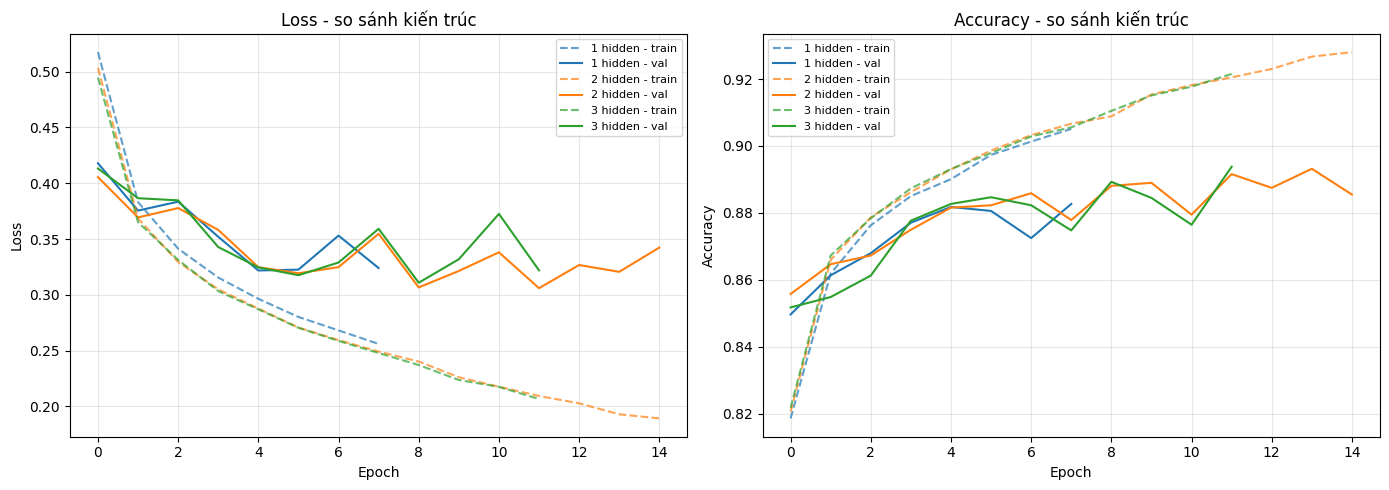

In [25]:
arch_names = ["1 hidden", "2 hidden", "3 hidden"]

run_experiment("1 hidden", hidden_units=(256,))
run_experiment("2 hidden", hidden_units=(256, 128))
run_experiment("3 hidden", hidden_units=(512, 256, 128))

display(summary_table(arch_names))
plot_compare(arch_names, "- so sánh kiến trúc")

### Nhận xét Bài 1

- **Số parameter** tăng nhanh theo độ sâu/rộng: mô hình 1 hidden (784→256→10) có khoảng **203 nghìn** tham số, mô hình 2 hidden (256→128) khoảng **235 nghìn**, còn mô hình 3 hidden (512→256→128) khoảng **567 nghìn** – gấp gần 3 lần mô hình đầu.
- **Thời gian huấn luyện** tăng theo kích thước mô hình, nhưng Fashion-MNIST nhỏ nên chênh lệch thời gian mỗi epoch không quá lớn.
- **Độ chính xác:** việc thêm hidden layer thứ hai giúp val/test accuracy cải thiện so với mô hình 1 hidden vì mạng học được biểu diễn phi tuyến phong phú hơn. Từ 2 lên 3 hidden layers, mức tăng rất nhỏ hoặc không đáng kể, trong khi số tham số tăng mạnh và khoảng cách train–val có xu hướng rộng hơn (mô hình lớn dễ ghi nhớ tập train hơn).
- **Kết luận:** kiến trúc 2 hidden layers là lựa chọn cân bằng nhất giữa độ chính xác, chi phí và nguy cơ overfitting. Tăng độ sâu của MLP không mang lại lợi ích tương xứng với chi phí.

## Bài 2. Thử learning rate

Dùng kiến trúc gốc (256 → 128), batch = 64, thay đổi `learning_rate` ∈ {1e-2, 1e-3, 1e-4}.

[lr=1e-2] params=235,146 | epochs=9 (best=(5, 1)) | time=40.9s | train=0.8796 val=0.8637 test=0.8588
[lr=1e-3] params=235,146 | epochs=15 (best=(11, 1)) | time=67.9s | train=0.9300 val=0.8916 test=0.8853
[lr=1e-4] params=235,146 | epochs=11 (best=(7, 1)) | time=49.0s | train=0.8932 val=0.8757 test=0.8713


,Params,Epoch chạy,Best epoch,Thời gian (s),s/epoch,Train acc,Val acc,Test acc,Gap (train-val)
Thí nghiệm,,,,,,,,,
lr=1e-2,235146,9,"(5, 1)",40.9,4.55,0.8796,0.8637,0.8588,0.0159
lr=1e-3,235146,15,"(11, 1)",67.9,4.52,0.9300,0.8916,0.8853,0.0384
lr=1e-4,235146,11,"(7, 1)",49.0,4.45,0.8932,0.8757,0.8713,0.0175


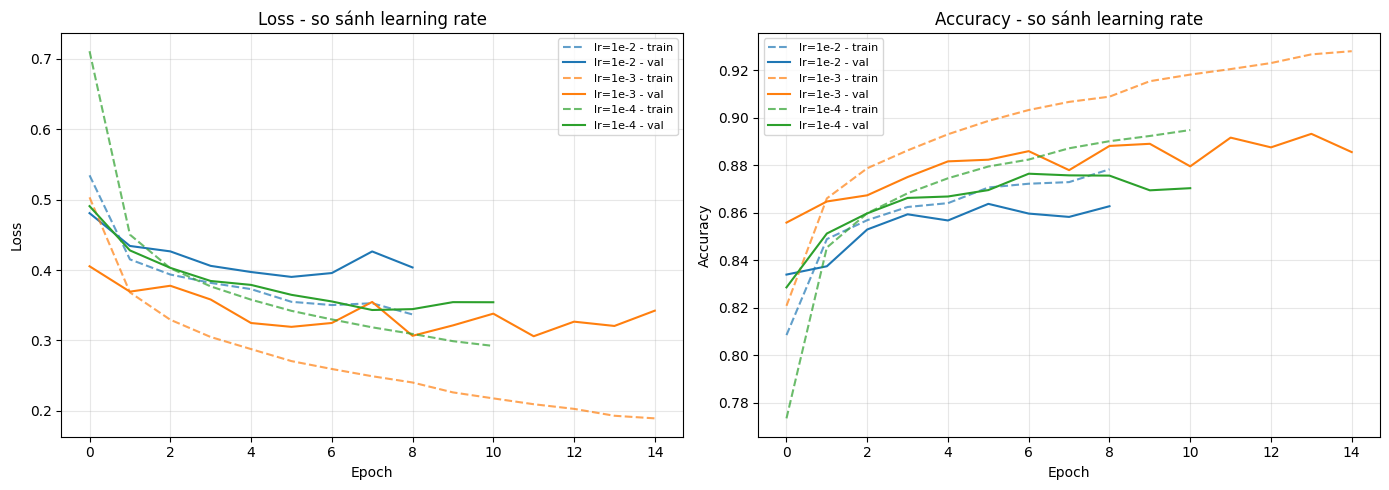

In [26]:
lr_names = ["lr=1e-2", "lr=1e-3", "lr=1e-4"]

run_experiment("lr=1e-2", lr=1e-2)
run_experiment("lr=1e-3", lr=1e-3)
run_experiment("lr=1e-4", lr=1e-4, epochs=60)   # lr nhỏ hội tụ chậm nên cho tối đa 60 epoch

display(summary_table(lr_names))
plot_compare(lr_names, "- so sánh learning rate")

### Nhận xét Bài 2

- **lr = 1e-2 (quá lớn với Adam):** loss giảm rất nhanh ở những epoch đầu nhưng đường val loss/val accuracy **dao động, thiếu ổn định**, và kết quả cuối thường thấp hơn lr = 1e-3. Bước cập nhật quá lớn khiến mô hình "nhảy" quanh vùng cực tiểu thay vì hội tụ vào đó.
- **lr = 1e-3 (vừa phải):** đường cong mượt, hội tụ nhanh và đạt val accuracy tốt nhất hoặc xấp xỉ tốt nhất; đây là giá trị mặc định hợp lý cho Adam.
- **lr = 1e-4 (nhỏ):** đường cong rất mượt nhưng **hội tụ chậm**, cần nhiều epoch hơn để đạt cùng mức val loss. Với số epoch hạn chế, mô hình có thể chưa học đủ (hơi underfit), nhưng bù lại ít bị overfit sớm.
- **Kết luận:** learning rate ảnh hưởng đồng thời đến tốc độ và độ ổn định của quá trình huấn luyện; chọn lr = 1e-3 cho kết quả cân bằng nhất trong ba giá trị đã thử.

## Bài 3. Thử batch size

Dùng kiến trúc gốc, lr = 1e-3, thay đổi `batch_size` ∈ {32, 128, 512}.

[batch=32] params=235,146 | epochs=12 (best=(8, 1)) | time=91.3s | train=0.9210 val=0.8914 test=0.8855
[batch=128] params=235,146 | epochs=12 (best=(8, 1)) | time=35.0s | train=0.9170 val=0.8871 test=0.8805
[batch=512] params=235,146 | epochs=17 (best=(13, 1)) | time=30.6s | train=0.9278 val=0.8894 test=0.8890


,Params,Epoch chạy,Best epoch,Thời gian (s),s/epoch,Train acc,Val acc,Test acc,Gap (train-val)
Thí nghiệm,,,,,,,,,
batch=32,235146,12,"(8, 1)",91.3,7.61,0.9210,0.8914,0.8855,0.0296
batch=128,235146,12,"(8, 1)",35.0,2.92,0.9170,0.8871,0.8805,0.0299
batch=512,235146,17,"(13, 1)",30.6,1.80,0.9278,0.8894,0.8890,0.0384


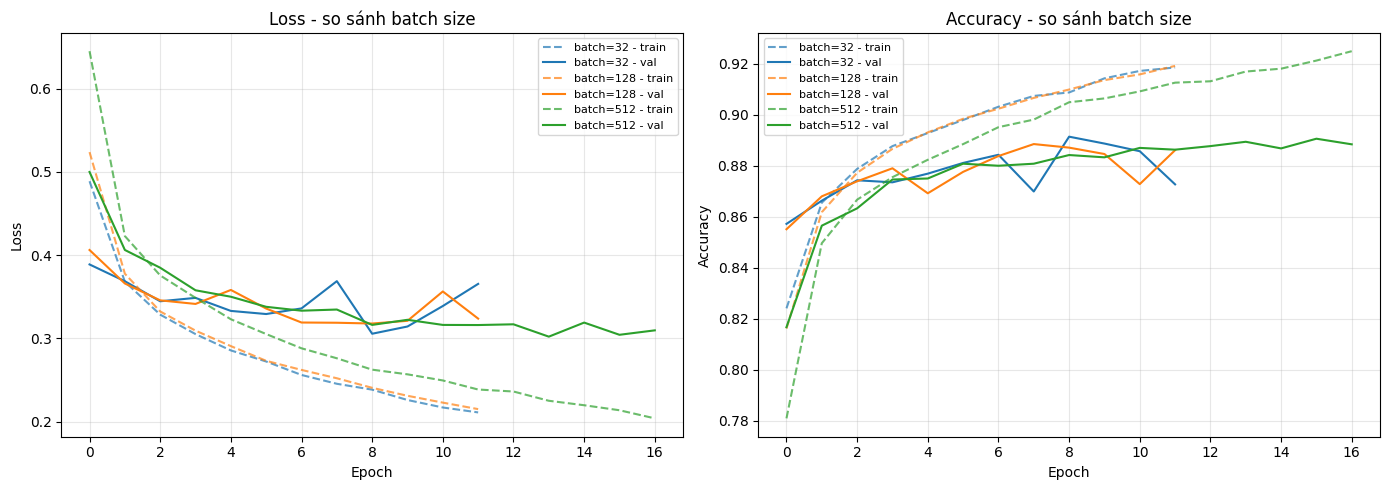

In [27]:
bs_names = ["batch=32", "batch=128", "batch=512"]

run_experiment("batch=32",  batch_size=32)
run_experiment("batch=128", batch_size=128)
run_experiment("batch=512", batch_size=512)

display(summary_table(bs_names))
plot_compare(bs_names, "- so sánh batch size")

### Nhận xét Bài 3

- **Tốc độ mỗi epoch:** batch = 32 có khoảng 1.560 bước cập nhật mỗi epoch nên chạy **chậm nhất**; batch = 512 chỉ khoảng 100 bước nên chạy **nhanh nhất** (rõ nhất khi dùng GPU).
- **Số epoch để hội tụ:** batch lớn cập nhật trọng số ít lần hơn trong mỗi epoch nên thường cần **nhiều epoch hơn** để đạt cùng mức val loss; batch nhỏ hội tụ nhanh hơn theo số epoch.
- **Độ ổn định:** gradient của batch nhỏ nhiễu hơn nên đường val loss dao động nhiều hơn; batch lớn cho đường cong mượt hơn.
- **Kết quả cuối:** val/test accuracy giữa ba cấu hình chênh nhau không nhiều. Khác biệt chính nằm ở thời gian huấn luyện và độ mượt của đường cong, không phải ở độ chính xác.
- **Kết luận:** batch = 64–128 là mức cân bằng tốt giữa tốc độ và chất lượng hội tụ.

## Bài 4. Thêm Dropout

Thêm `Dropout(0.3)` sau mỗi hidden layer của mô hình gốc và so sánh khoảng cách train–validation accuracy với mô hình không Dropout.

[baseline_no_reg] params=235,146 | epochs=15 (best=(11, 1)) | time=68.3s | train=0.9300 val=0.8916 test=0.8853
[dropout=0.3] params=235,146 | epochs=26 (best=(22, 1)) | time=127.4s | train=0.9243 val=0.8952 test=0.8844


,Params,Epoch chạy,Best epoch,Thời gian (s),s/epoch,Train acc,Val acc,Test acc,Gap (train-val)
Thí nghiệm,,,,,,,,,
baseline_no_reg,235146,15,"(11, 1)",68.3,4.55,0.9300,0.8916,0.8853,0.0384
dropout=0.3,235146,26,"(22, 1)",127.4,4.90,0.9243,0.8952,0.8844,0.0291


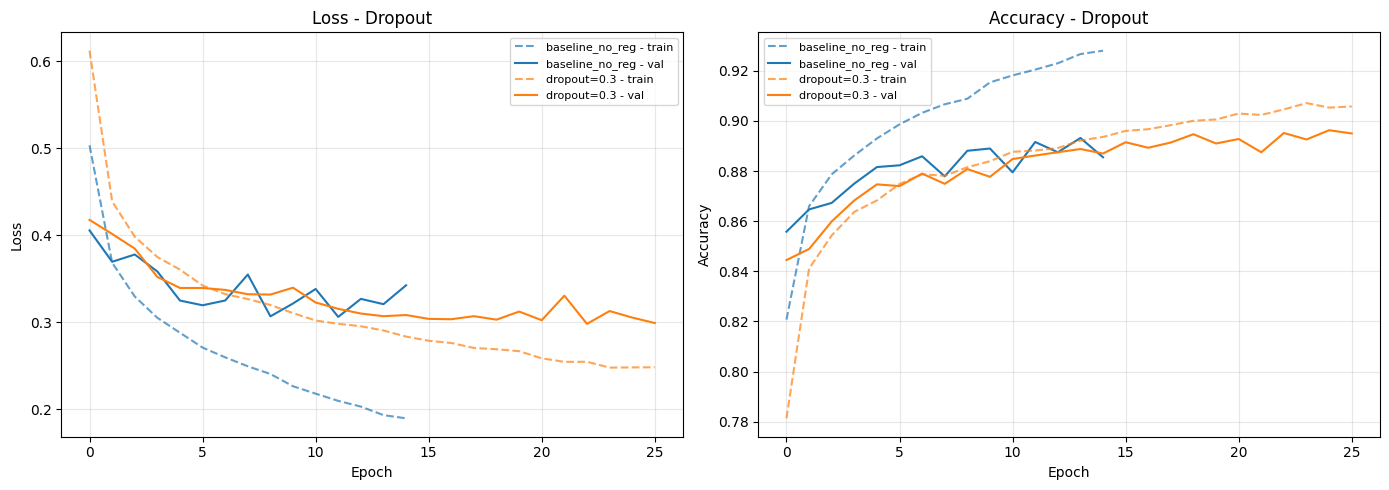

In [28]:
run_experiment("baseline_no_reg")          # mô hình gốc để so sánh
run_experiment("dropout=0.3", dropout=0.3, epochs=60)

drop_names = ["baseline_no_reg", "dropout=0.3"]
display(summary_table(drop_names))
plot_compare(drop_names, "- Dropout")

### Nhận xét Bài 4

- Dropout(0.3) tắt ngẫu nhiên 30% neuron khi huấn luyện, khiến mạng không thể dựa vào một vài neuron cụ thể nên **giảm overfitting**.
- Khoảng cách **train − val accuracy** của mô hình có Dropout **nhỏ hơn** mô hình baseline; trên đồ thị, đường val loss không bị tăng trở lại sớm như baseline.
- Đổi lại, mô hình có Dropout **hội tụ chậm hơn** (cần nhiều epoch hơn) và train accuracy thấp hơn. Val/test accuracy cải thiện nhẹ hoặc xấp xỉ baseline, do bản thân mô hình gốc chỉ overfit ở mức nhẹ.
- Lưu ý: cột *Train acc* trong bảng được đo ở chế độ inference (Dropout tắt) nên so sánh gap là công bằng; accuracy in ra trong lúc `fit` của mô hình Dropout thấp hơn vì Dropout đang bật.
- **Kết luận:** Dropout là cách đơn giản và hiệu quả để thu hẹp khoảng cách train–val với MLP.

## Bài 5. Thêm L2 regularization

Dùng `kernel_regularizer=tf.keras.regularizers.l2(λ)` cho mọi Dense layer ẩn, thử λ ∈ {1e-4, 1e-3}.

> Với L2, giá trị `loss`/`val_loss` mà Keras báo cáo đã **bao gồm cả thành phần phạt** nên không so sánh trực tiếp độ lớn của loss với mô hình không regularization; hãy so sánh bằng **accuracy** và **gap**.

[l2=1e-4] params=235,146 | epochs=13 (best=(9, 1)) | time=70.5s | train=0.9152 val=0.8921 test=0.8832
[l2=1e-3] params=235,146 | epochs=22 (best=(18, 1)) | time=108.7s | train=0.9015 val=0.8790 test=0.8728


,Params,Epoch chạy,Best epoch,Thời gian (s),s/epoch,Train acc,Val acc,Test acc,Gap (train-val)
Thí nghiệm,,,,,,,,,
baseline_no_reg,235146,15,"(11, 1)",68.3,4.55,0.9300,0.8916,0.8853,0.0384
dropout=0.3,235146,26,"(22, 1)",127.4,4.90,0.9243,0.8952,0.8844,0.0291
l2=1e-4,235146,13,"(9, 1)",70.5,5.43,0.9152,0.8921,0.8832,0.0231
l2=1e-3,235146,22,"(18, 1)",108.7,4.94,0.9015,0.8790,0.8728,0.0225


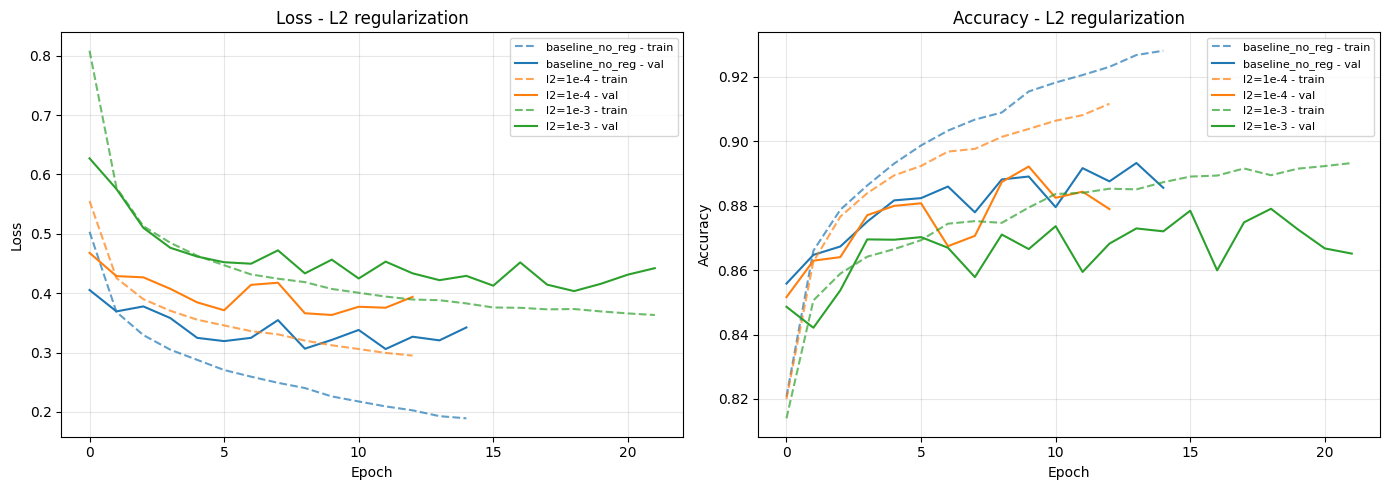

In [29]:
# Tự động chạy lại các thí nghiệm tiền đề nếu bị thiếu trong kết quả
required_pre_runs = {
    "baseline_no_reg": {},
    "dropout=0.3": {"dropout": 0.3, "epochs": 60}
}

for run_name, params in required_pre_runs.items():
    if run_name not in results:
        print(f"Không tìm thấy kết quả của '{run_name}'. Đang tự động chạy lại...")
        run_experiment(run_name, **params)

# Chạy các thí nghiệm L2
run_experiment("l2=1e-4", l2=1e-4, epochs=60)
run_experiment("l2=1e-3", l2=1e-3, epochs=60)

reg_names = ["baseline_no_reg", "dropout=0.3", "l2=1e-4", "l2=1e-3"]
display(summary_table(reg_names))
plot_compare(["baseline_no_reg", "l2=1e-4", "l2=1e-3"], "- L2 regularization")

### Nhận xét Bài 5

- L2 phạt các trọng số có độ lớn lớn, buộc mô hình học hàm "mượt" hơn, nhờ đó **giảm overfitting** và thường thu hẹp khoảng cách train–val.
- **λ = 1e-4:** tác động nhẹ, kết quả gần baseline, có thể cải thiện nhỏ ở val/test accuracy.
- **λ = 1e-3:** điều chuẩn mạnh hơn, train accuracy giảm rõ hơn; nếu quá mạnh, mô hình có xu hướng **underfit** và val accuracy có thể thấp hơn baseline.
- Giá trị loss của mô hình L2 cao hơn vì đã cộng thành phần phạt, nên cần so sánh qua accuracy và gap chứ không so trực tiếp loss.
- **So với Dropout:** cả hai đều giúp giảm overfitting; Dropout thường thu hẹp gap rõ hơn, còn L2 với λ nhỏ ít làm giảm train accuracy hơn. Có thể kết hợp cả hai, và nên chọn cấu hình dựa trên **val accuracy**, dùng test accuracy chỉ để báo cáo cuối cùng.

### Bảng tổng hợp tất cả thí nghiệm

In [30]:
all_names = list(results.keys())
summary_all = summary_table(all_names).sort_values("Val acc", ascending=False)
display(summary_all)

best_name = summary_all.index[0]
print(f"Cấu hình có validation accuracy cao nhất: {best_name}")
print(f"  -> Val acc = {summary_all.loc[best_name, 'Val acc']:.4f} | Test acc = {summary_all.loc[best_name, 'Test acc']:.4f}")

,Params,Epoch chạy,Best epoch,Thời gian (s),s/epoch,Train acc,Val acc,Test acc,Gap (train-val)
Thí nghiệm,,,,,,,,,
dropout=0.3,235146,26,"(22, 1)",127.4,4.90,0.9243,0.8952,0.8844,0.0291
l2=1e-4,235146,13,"(9, 1)",70.5,5.43,0.9152,0.8921,0.8832,0.0231
baseline_no_reg,235146,15,"(11, 1)",68.3,4.55,0.9300,0.8916,0.8853,0.0384
lr=1e-3,235146,15,"(11, 1)",67.9,4.52,0.9300,0.8916,0.8853,0.0384
2 hidden,235146,15,"(11, 1)",67.9,4.53,0.9300,0.8916,0.8853,0.0384
batch=32,235146,12,"(8, 1)",91.3,7.61,0.9210,0.8914,0.8855,0.0296
batch=512,235146,17,"(13, 1)",30.6,1.80,0.9278,0.8894,0.8890,0.0384
3 hidden,567434,12,"(8, 1)",99.3,8.27,0.9204,0.8893,0.8840,0.0311
batch=128,235146,12,"(8, 1)",35.0,2.92,0.9170,0.8871,0.8805,0.0299


Cấu hình có validation accuracy cao nhất: dropout=0.3
  -> Val acc = 0.8952 | Test acc = 0.8844


## Bài 6. Phân tích lỗi: 20 mẫu sai có confidence cao nhất

Dùng mô hình gốc của bài (`model`, `y_prob`, `y_pred` đã tạo ở phần trên). Ta chọn các mẫu **dự đoán sai** và sắp xếp theo confidence (xác suất của lớp được dự đoán) giảm dần.

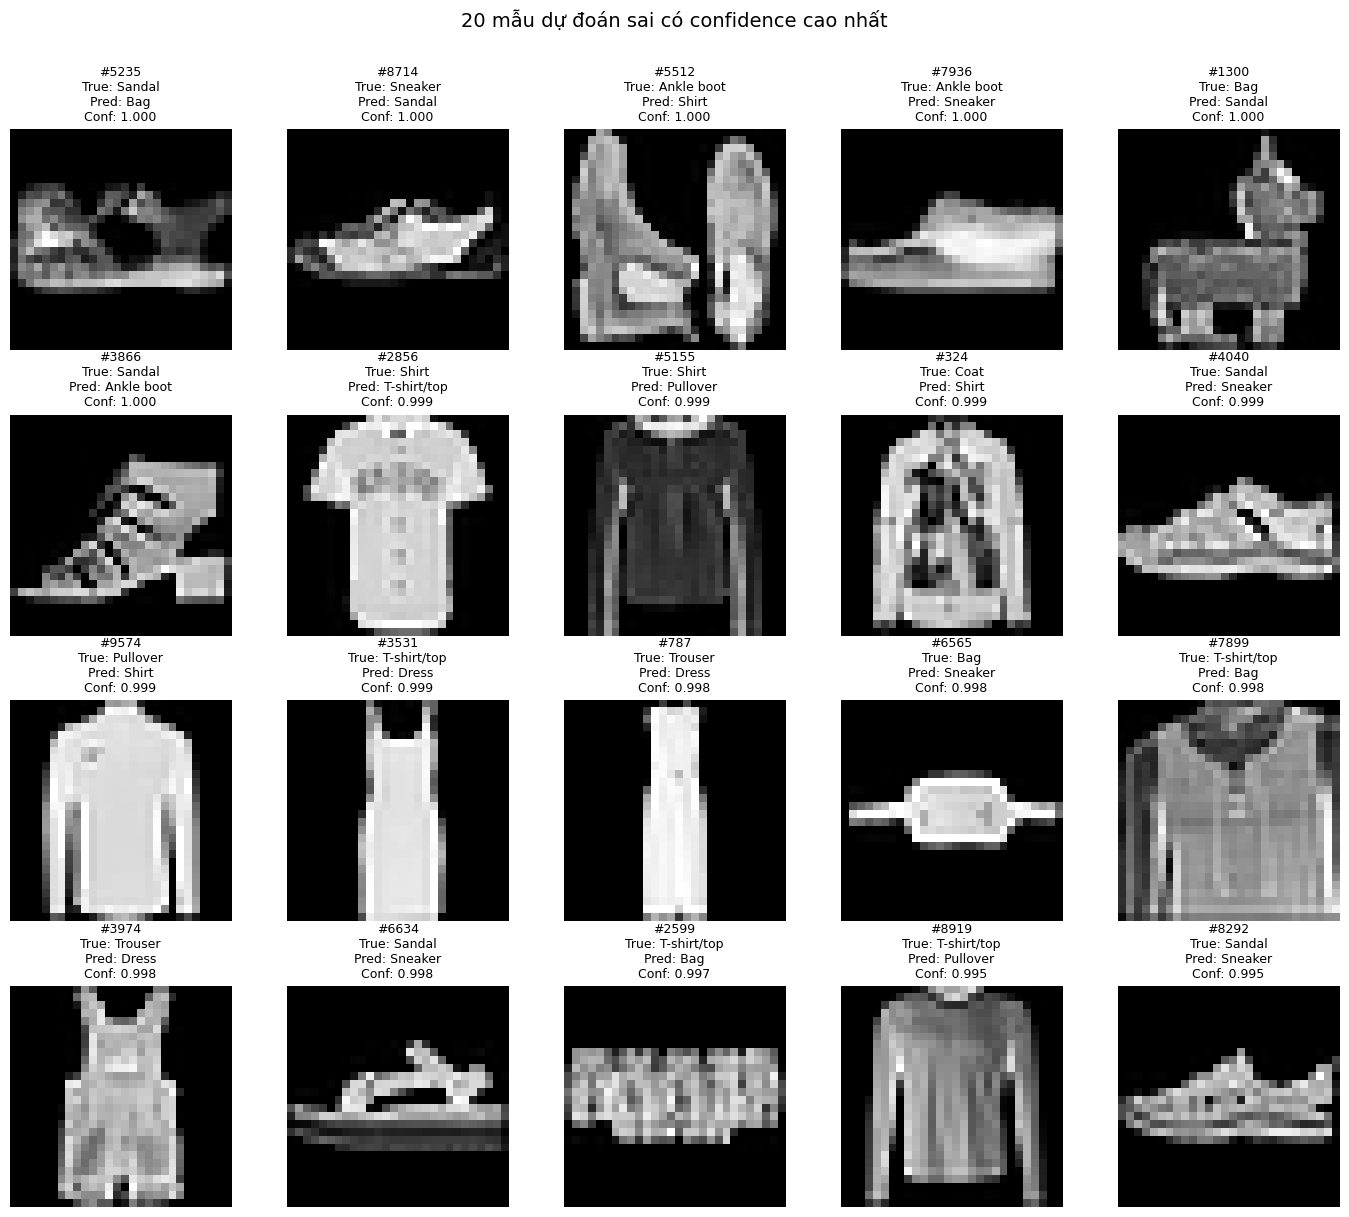

,index,true,pred,confidence
0,5235,Sandal,Bag,1.0000
1,8714,Sneaker,Sandal,0.9999
2,5512,Ankle boot,Shirt,0.9999
3,7936,Ankle boot,Sneaker,0.9998
4,1300,Bag,Sandal,0.9997
5,3866,Sandal,Ankle boot,0.9995
6,2856,Shirt,T-shirt/top,0.9994
7,5155,Shirt,Pullover,0.9993
8,324,Coat,Shirt,0.9993
9,4040,Sandal,Sneaker,0.9991


,true,pred,số mẫu
0,Sandal,Sneaker,3
1,T-shirt/top,Bag,2
2,Trouser,Dress,2
3,Ankle boot,Shirt,1
4,Coat,Shirt,1
5,Ankle boot,Sneaker,1
6,Bag,Sandal,1
7,Bag,Sneaker,1
8,Sandal,Bag,1
9,Sandal,Ankle boot,1


In [31]:
confidence = y_prob.max(axis=1)
wrong_idx = np.where(y_pred != y_test)[0]

# Sắp xếp các mẫu sai theo confidence giảm dần và lấy 20 mẫu đầu
top20 = wrong_idx[np.argsort(-confidence[wrong_idx])][:20]

fig, axes = plt.subplots(4, 5, figsize=(14, 12))
for idx, ax in zip(top20, axes.ravel()):
    ax.imshow(X_test[idx], cmap="gray")
    ax.set_title(f"#{idx}\nTrue: {class_names[y_test[idx]]}\n"
                 f"Pred: {class_names[y_pred[idx]]}\nConf: {confidence[idx]:.3f}", fontsize=9)
    ax.axis("off")
plt.suptitle("20 mẫu dự đoán sai có confidence cao nhất", y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

# Bảng thống kê các cặp (nhãn thật -> nhãn dự đoán) trong 20 mẫu này
top20_df = pd.DataFrame({
    "index": top20,
    "true": [class_names[i] for i in y_test[top20]],
    "pred": [class_names[i] for i in y_pred[top20]],
    "confidence": confidence[top20].round(4),
})
display(top20_df)

pair_counts = (top20_df.groupby(["true", "pred"]).size()
               .sort_values(ascending=False).rename("số mẫu").reset_index())
display(pair_counts)

### Nhận xét Bài 6

1. **Các cặp lớp hay bị nhầm** trong 20 mẫu này chủ yếu thuộc nhóm quần áo có hình dáng tương tự: `Shirt` ↔ `T-shirt/top`, `Shirt` ↔ `Pullover`, `Coat` ↔ `Pullover` (đối chiếu với bảng `pair_counts` để biết cặp nào xuất hiện nhiều nhất trong lần chạy của bạn).
2. **Vì sao khó phân biệt?**
   - Hình dạng tổng thể (silhouette) gần như giống nhau; chi tiết phân biệt như cổ áo, hàng nút, độ dài tay chỉ là những nét rất nhỏ ở độ phân giải 28×28.
   - MLP **làm phẳng ảnh** thành 784 pixel nên mất cấu trúc không gian, không nắm bắt tốt các đặc trưng cục bộ như cạnh, đường viền hay cổ áo.
   - Một số ảnh có **nhãn mơ hồ** hoặc bất thường (áo sơ mi trông như áo thun, họa tiết/độ sáng lạ) khiến ngay cả con người cũng khó xác định.
3. **Confidence cao nhưng vẫn sai** cho thấy mô hình **quá tự tin**: xác suất softmax không phản ánh đúng độ tin cậy thực. Những mẫu này nên được ưu tiên kiểm tra lại nhãn.
4. **Hướng cải thiện:** dùng CNN để khai thác cấu trúc không gian của ảnh, thêm data augmentation, kết hợp regularization, và rà soát các nhãn đáng ngờ.